# A5b — Tree-Based Regression

Goal: compare tree-based models (Random Forest, XGBoost variants) for the AimoScore regression task and compare against the previous champion (~R² 0.607).

## Imports + paths + load data

In [416]:
import sys
print(sys.executable)

import warnings
warnings.filterwarnings("ignore", message="`artifact_path` is deprecated")
warnings.filterwarnings("ignore", category=FutureWarning, module="mlflow")

from urllib3.exceptions import InsecureRequestWarning
warnings.simplefilter("ignore", InsecureRequestWarning)

/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/ml/models/.venv/bin/python


In [417]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Notebook location: ml/models/research/A5b/Regression/
REG_PATH = Path("../../../data/raw/AimoScore_WeakLink_big_scores.xls")

df_reg = pd.read_excel(REG_PATH)
print("regression:", df_reg.shape)
display(df_reg.head(2))

regression: (2094, 43)


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,...,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,...,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,...,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect


## Common utilities

In [418]:
from typing import Dict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": rmse(y_true, y_pred),
        "mae": float(mean_absolute_error(y_true, y_pred)),
    }

## MLflow setup

In [419]:
import mlflow
from dotenv import load_dotenv, find_dotenv
from os import getenv

load_dotenv(find_dotenv())

tracking_uri = getenv("MLFLOW_TRACKING_URI")
if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    print("WARNING: MLFLOW_TRACKING_URI not set. MLflow will use its default local tracking location.")

EXPERIMENT_NAME = "A5b_tree_regression"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A5b_tree_regression


## Dataset preparation

In [420]:
from sklearn.model_selection import train_test_split

# Target
y = df_reg["AimoScore"].astype(float)

# Features — drop target, estimated score, and ID
X = df_reg.drop(columns=["AimoScore", "EstimatedScore", "ID"], errors="ignore")
X = X.apply(pd.to_numeric, errors="coerce")

print("X:", X.shape, "  y:", y.shape)
print("Missing values in X:", int(X.isna().sum().sum()))
print(f"Target range: {y.min():.4f} – {y.max():.4f}")

# 80/20 split — same seed used across all A5b experiments
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
print("Train:", X_train.shape, "  Test:", X_test.shape)

X: (2094, 40)   y: (2094,)
Missing values in X: 0
Target range: 0.0100 – 0.9940
Train: (1675, 40)   Test: (419, 40)


## Model helper

In [421]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

results: Dict[str, Dict] = {}


def train_and_log(name: str, pipeline: Pipeline, params: Dict) -> Dict[str, float]:
    """Fit pipeline, evaluate, log to MLflow, store in results dict."""
    pipeline.fit(X_train, y_train)

    train_m = regression_metrics(y_train, pipeline.predict(X_train))
    test_m  = regression_metrics(y_test,  pipeline.predict(X_test))

    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_params({
            "random_seed": RANDOM_SEED,
            "train_size": int(X_train.shape[0]),
            "test_size": int(X_test.shape[0]),
            "n_features": int(X_train.shape[1]),
        })
        for k, v in train_m.items():
            mlflow.log_metric(f"train_{k}", v)
        for k, v in test_m.items():
            mlflow.log_metric(f"test_{k}", v)
        mlflow.sklearn.log_model(pipeline, name="model")

    results[name] = {"pipeline": pipeline, "train": train_m, "test": test_m}

    print(f"{name}")
    print(f"  Train  R²={train_m['r2']:.4f}  RMSE={train_m['rmse']:.4f}  MAE={train_m['mae']:.4f}")
    print(f"  Test   R²={test_m['r2']:.4f}  RMSE={test_m['rmse']:.4f}  MAE={test_m['mae']:.4f}")
    return test_m

---
## 2 — Random Forest

In [422]:
from sklearn.ensemble import RandomForestRegressor

rf_params = {
    "model": "RandomForestRegressor",
    "n_estimators": 200,
    "max_depth": None,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "bootstrap": True,
}

rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        max_features="sqrt",
        min_samples_leaf=1,
        bootstrap=True,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("RandomForest_baseline", rf_pipe, rf_params)

2026/03/04 00:25:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run RandomForest_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/eba41bc1472c45d5b68fe8fafcdbdc6d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
RandomForest_baseline
  Train  R²=0.9558  RMSE=0.0493  MAE=0.0364
  Test   R²=0.7236  RMSE=0.1285  MAE=0.0949


{'r2': 0.7235824118691092,
 'rmse': 0.12846830681278226,
 'mae': 0.09488486618306312}

### Random Forest — feature importance

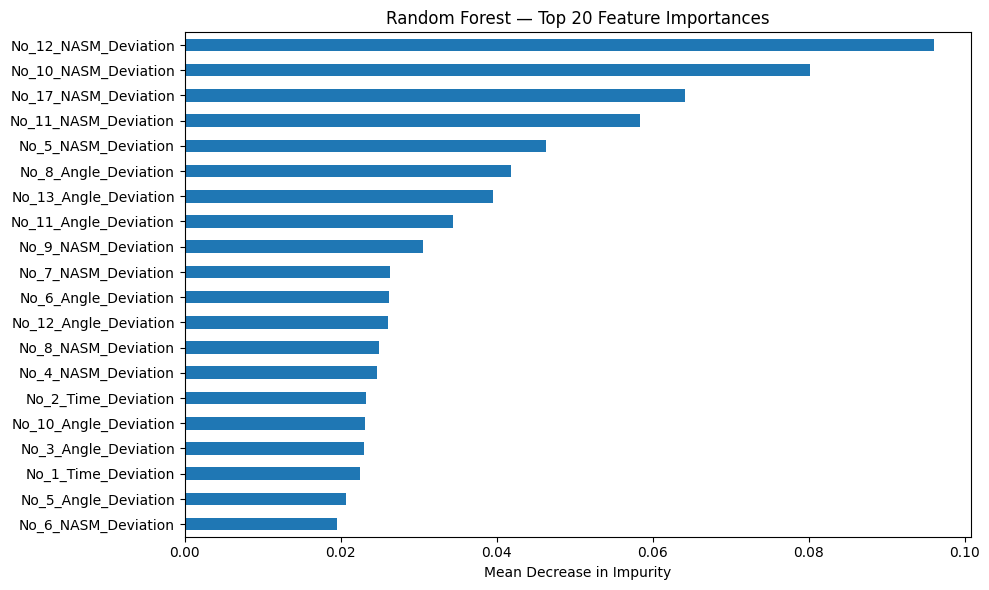

In [423]:
rf_model = results["RandomForest_baseline"]["pipeline"].named_steps["model"]

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top20 = importances.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
top20.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Random Forest — Top 20 Feature Importances")
ax.set_xlabel("Mean Decrease in Impurity")
plt.tight_layout()
plt.show()

---
### Random Forest — tuned

Parameters selected from a prior randomised search: more features per split (`max_features=0.5`), stricter split criterion (`min_samples_split=5`), and a depth cap (`max_depth=40`) to reduce overfitting.

In [424]:
rf_tuned_params = {
    "model": "RandomForestRegressor",
    "n_estimators": 1000,
    "max_features": 0.5,
    "min_samples_leaf": 1,
    "min_samples_split": 5,
    "max_depth": 40,
    "max_samples": None,
    "bootstrap": True,
}

rf_tuned_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=1000,
        max_features=0.5,
        min_samples_leaf=1,
        min_samples_split=5,
        max_depth=40,
        max_samples=None,
        bootstrap=True,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("RandomForest_tuned", rf_tuned_pipe, rf_tuned_params)

2026/03/04 00:25:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run RandomForest_tuned at: https://172.27.62.170:5001/#/experiments/9/runs/4e892654ca15451594f455e646befb73
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
RandomForest_tuned
  Train  R²=0.9485  RMSE=0.0532  MAE=0.0384
  Test   R²=0.7423  RMSE=0.1240  MAE=0.0907


{'r2': 0.7422956068921295,
 'rmse': 0.12404351796770974,
 'mae': 0.09065065057682767}

---
## 3 — XGBoost

In [425]:
from xgboost import XGBRegressor

xgb_params = {
    "model": "XGBRegressor",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
}

xgb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        reg_alpha=0.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("XGBoost_baseline", xgb_pipe, xgb_params)

2026/03/04 00:26:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run XGBoost_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/8f44330d68a047ea8af36dbcaa451517
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
XGBoost_baseline
  Train  R²=0.9997  RMSE=0.0042  MAE=0.0030
  Test   R²=0.7600  RMSE=0.1197  MAE=0.0864


{'r2': 0.7600366228932536,
 'rmse': 0.11969765612178654,
 'mae': 0.08635647543836243}

### XGBoost — feature importance

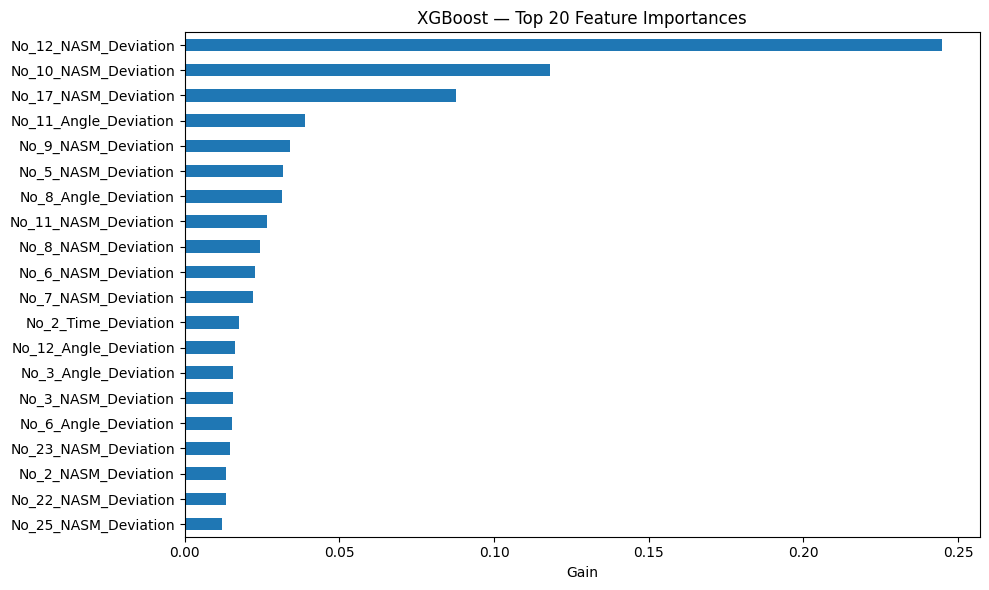

In [426]:
xgb_model = results["XGBoost_baseline"]["pipeline"].named_steps["model"]

xgb_importances = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
)
top20_xgb = xgb_importances.sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
top20_xgb.sort_values().plot(kind="barh", ax=ax)
ax.set_title("XGBoost — Top 20 Feature Importances")
ax.set_xlabel("Gain")
plt.tight_layout()
plt.show()

### XGBoost experiment 1 — shallower trees + lower learning rate + more estimators

The baseline overfits hard (train R²≈1.0). Reducing `max_depth` and learning rate while adding more trees forces the model to learn in smaller steps and prevents individual trees from memorising the data.

In [427]:
xgb1_params = {
    "model": "XGBRegressor",
    "n_estimators": 1000,
    "learning_rate": 0.02,
    "max_depth": 4,
    "min_child_weight": 3,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_lambda": 2.0,
    "reg_alpha": 0.1,
    "objective": "reg:squarederror",
    "tree_method": "hist",
}

xgb1_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(
        n_estimators=1000,
        learning_rate=0.02,
        max_depth=4,
        min_child_weight=3,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_lambda=2.0,
        reg_alpha=0.1,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("XGBoost_exp1_shallow_slow", xgb1_pipe, xgb1_params)

2026/03/04 00:26:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run XGBoost_exp1_shallow_slow at: https://172.27.62.170:5001/#/experiments/9/runs/1586a95ab7d54b9c85edad11597609d9
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
XGBoost_exp1_shallow_slow
  Train  R²=0.9601  RMSE=0.0468  MAE=0.0342
  Test   R²=0.7628  RMSE=0.1190  MAE=0.0858


{'r2': 0.7628042609312113,
 'rmse': 0.11900538268076978,
 'mae': 0.08578840937337742}

### XGBoost experiment 3 — low learning rate + more trees

In [428]:
xgb3_params = {
    "model": "XGBRegressor",
    "n_estimators": 1000,
    "learning_rate": 0.01,
    "max_depth": 6,
    "min_child_weight": 2,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
}

xgb3_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(
        n_estimators=1000,
        learning_rate=0.01,
        max_depth=6,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        reg_alpha=0.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("XGBoost_exp3_low_lr", xgb3_pipe, xgb3_params)

2026/03/04 00:26:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run XGBoost_exp3_low_lr at: https://172.27.62.170:5001/#/experiments/9/runs/51f4c60e9de7431fa81ec2f41f223d57
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
XGBoost_exp3_low_lr
  Train  R²=0.9867  RMSE=0.0270  MAE=0.0197
  Test   R²=0.7638  RMSE=0.1188  MAE=0.0855


{'r2': 0.7637730371644078,
 'rmse': 0.11876210776600227,
 'mae': 0.0855293562613857}

---
## 6 — Extra Trees

Extra Trees (Extremely Randomised Trees) chooses split thresholds randomly rather than searching for the optimal split at each node. The extra randomness acts as a strong regulariser that tends to reduce variance on small datasets, at the cost of slightly higher bias.

In [429]:
from sklearn.ensemble import ExtraTreesRegressor

et_params = {
    "model": "ExtraTreesRegressor",
    "n_estimators": 200,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "bootstrap": False,
}

et_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesRegressor(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=1,
        bootstrap=False,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

train_and_log("ExtraTrees_baseline", et_pipe, et_params)

2026/03/04 00:26:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run ExtraTrees_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/4348df4ba22a45fd9b2fd665fd8c789e
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
ExtraTrees_baseline
  Train  R²=1.0000  RMSE=0.0000  MAE=0.0000
  Test   R²=0.7005  RMSE=0.1337  MAE=0.0977


{'r2': 0.700486211490013,
 'rmse': 0.13372776118119742,
 'mae': 0.09772477697223812}

In [430]:
from sklearn.base import BaseEstimator, TransformerMixin


class ColumnDropper(BaseEstimator, TransformerMixin):
    """Drop a fixed list of columns by name."""
    def __init__(self, cols_to_drop):
        self.cols_to_drop = cols_to_drop

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=self.cols_to_drop, errors="ignore")

---
## 8 — XGBoost exp3 with 5 least important features removed (XGBoost importances)

Uses XGBoost's own feature importances to identify the 5 least useful features and drops them from the pipeline. Directly comparable to `XGBoost_exp3_low_lr` to isolate the effect of feature removal.

In [431]:
# 5 least important features according to XGBoost baseline
xgb_bottom5_features = (
    xgb_importances.sort_values(ascending=True).head(5).index.tolist()
)
print("5 least important features (XGBoost):")
for f in xgb_bottom5_features:
    print(f"  {f}  ({xgb_importances[f]:.6f})")

xgb_exp3_xgb_drop5_pipe = Pipeline([
    ("drop_features", ColumnDropper(xgb_bottom5_features)),
    ("imputer",       SimpleImputer(strategy="median")),
    ("model",         XGBRegressor(
        n_estimators=1000,
        learning_rate=0.01,
        max_depth=6,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        reg_alpha=0.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ))
])

xgb_exp3_xgb_drop5_params = {
    "model": "XGBRegressor",
    "n_estimators": 1000,
    "learning_rate": 0.01,
    "max_depth": 6,
    "min_child_weight": 2,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "dropped_features": str(xgb_bottom5_features),
    "importance_source": "XGBoost",
}

train_and_log("XGBoost_exp3_xgb_drop5", xgb_exp3_xgb_drop5_pipe, xgb_exp3_xgb_drop5_params)

5 least important features (XGBoost):
  No_2_Angle_Deviation  (0.004901)
  No_15_NASM_Deviation  (0.005901)
  No_16_NASM_Deviation  (0.006846)
  No_4_NASM_Deviation  (0.007424)
  No_1_Angle_Deviation  (0.007968)


2026/03/04 00:26:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run XGBoost_exp3_xgb_drop5 at: https://172.27.62.170:5001/#/experiments/9/runs/2d9ed4a789d34caa9ce75d45609445ea
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
XGBoost_exp3_xgb_drop5
  Train  R²=0.9856  RMSE=0.0282  MAE=0.0204
  Test   R²=0.7649  RMSE=0.1185  MAE=0.0846


{'r2': 0.7649443201537524,
 'rmse': 0.11846731310442642,
 'mae': 0.08461863650293258}

---
## Results comparison

In [432]:
rows = []
for name, info in results.items():
    rows.append({
        "model": name,
        "train_r2":   info["train"]["r2"],
        "train_rmse": info["train"]["rmse"],
        "train_mae":  info["train"]["mae"],
        "test_r2":    info["test"]["r2"],
        "test_rmse":  info["test"]["rmse"],
        "test_mae":   info["test"]["mae"],
    })

comparison = (
    pd.DataFrame(rows)
    .sort_values("test_r2", ascending=False)
    .reset_index(drop=True)
)

display(
    comparison.style.format({
        "train_r2": "{:.4f}", "train_rmse": "{:.4f}", "train_mae": "{:.4f}",
        "test_r2":  "{:.4f}", "test_rmse":  "{:.4f}", "test_mae":  "{:.4f}",
    }).background_gradient(subset=["test_r2"], cmap="RdYlGn")
)

best = comparison.iloc[0]
print(f"\nBest model: {best['model']}")
print(f"  Test R²={best['test_r2']:.4f}  RMSE={best['test_rmse']:.4f}  MAE={best['test_mae']:.4f}")


,model,train_r2,train_rmse,train_mae,test_r2,test_rmse,test_mae
0,XGBoost_exp3_xgb_drop5,0.9856,0.0282,0.0204,0.7649,0.1185,0.0846
1,XGBoost_exp3_low_lr,0.9867,0.0270,0.0197,0.7638,0.1188,0.0855
2,XGBoost_exp1_shallow_slow,0.9601,0.0468,0.0342,0.7628,0.1190,0.0858
3,XGBoost_baseline,0.9997,0.0042,0.0030,0.7600,0.1197,0.0864
4,RandomForest_tuned,0.9485,0.0532,0.0384,0.7423,0.1240,0.0907
5,RandomForest_baseline,0.9558,0.0493,0.0364,0.7236,0.1285,0.0949
6,ExtraTrees_baseline,1.0000,0.0000,0.0000,0.7005,0.1337,0.0977



Best model: XGBoost_exp3_xgb_drop5
  Test R²=0.7649  RMSE=0.1185  MAE=0.0846


### Actual vs Predicted — best model

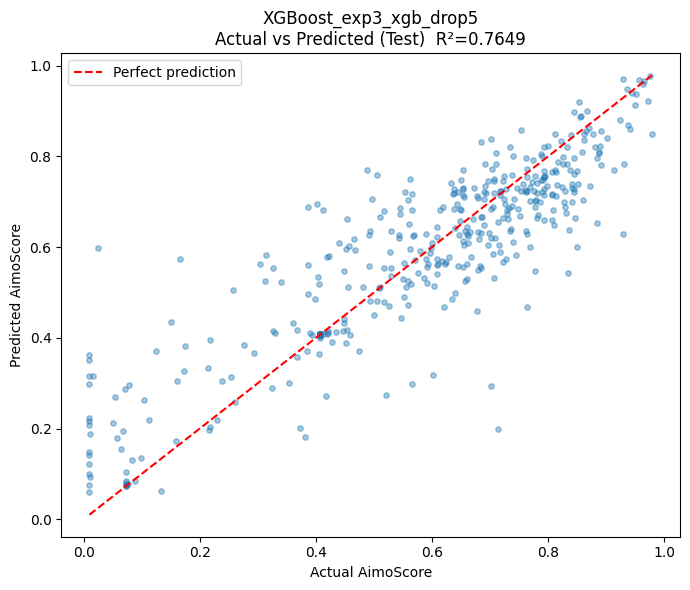

In [433]:
best_name = comparison.iloc[0]["model"]
best_pipe = results[best_name]["pipeline"]
y_pred_best = best_pipe.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_best, alpha=0.4, s=15)
lo, hi = float(y_test.min()), float(y_test.max())
ax.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
ax.set_xlabel("Actual AimoScore")
ax.set_ylabel("Predicted AimoScore")
test_r2 = results[best_name]["test"]["r2"]
ax.set_title(f"{best_name}\nActual vs Predicted (Test)  R²={test_r2:.4f}")
ax.legend()
plt.tight_layout()
plt.show()

---
## Cross-validation

5-fold CV on the training set gives per-fold R² scores for every model. Using the same folds across all models keeps the comparison fair and enables a paired t-test later.

In [434]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.base import clone

CV_FOLDS = 10
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)

cv_pipelines = {
    "RandomForest_baseline":     rf_pipe,
    "RandomForest_tuned":        rf_tuned_pipe,
    "XGBoost_baseline":          xgb_pipe,
    "XGBoost_exp1_shallow_slow": xgb1_pipe,
    "XGBoost_exp3_low_lr":       xgb3_pipe,
    "ExtraTrees_baseline":       et_pipe,
    "XGBoost_exp3_xgb_drop5":   xgb_exp3_xgb_drop5_pipe,
}

cv_scores: Dict[str, np.ndarray] = {}

for name, pipe in cv_pipelines.items():
    scores = cross_val_score(
        clone(pipe),
        X_train, y_train,
        cv=kf,
        scoring="r2",
        n_jobs=-1,
    )
    cv_scores[name] = scores
    print(f"{name}")
    print(f"  Fold R²: {[f'{s:.4f}' for s in scores]}")
    print(f"  Mean={scores.mean():.4f}  Std={scores.std():.4f}\n")

RandomForest_baseline
  Fold R²: ['0.6367', '0.7377', '0.6936', '0.7267', '0.6661', '0.6153', '0.7073', '0.6619', '0.7091', '0.5773']
  Mean=0.6732  Std=0.0489

RandomForest_tuned
  Fold R²: ['0.6512', '0.7633', '0.7172', '0.7671', '0.6919', '0.6461', '0.7104', '0.7062', '0.7379', '0.5767']
  Mean=0.6968  Std=0.0555

XGBoost_baseline
  Fold R²: ['0.6420', '0.7742', '0.7366', '0.7740', '0.7134', '0.6421', '0.7115', '0.7284', '0.7761', '0.5946']
  Mean=0.7093  Std=0.0602

XGBoost_exp1_shallow_slow
  Fold R²: ['0.6608', '0.7685', '0.7330', '0.7684', '0.7195', '0.6213', '0.6991', '0.7085', '0.7725', '0.5941']
  Mean=0.7046  Std=0.0591

XGBoost_exp3_low_lr
  Fold R²: ['0.6652', '0.7829', '0.7514', '0.7739', '0.7286', '0.6361', '0.7155', '0.7241', '0.7840', '0.5901']
  Mean=0.7152  Std=0.0622

ExtraTrees_baseline
  Fold R²: ['0.5821', '0.7416', '0.6712', '0.7296', '0.6446', '0.6045', '0.6845', '0.6418', '0.7077', '0.5966']
  Mean=0.6604  Std=0.0531

XGBoost_exp3_xgb_drop5
  Fold R²: ['0.6667

,model,cv_r2_mean,cv_r2_std
0,XGBoost_exp3_low_lr,0.7152,0.0622
1,XGBoost_exp3_xgb_drop5,0.7145,0.0603
2,XGBoost_baseline,0.7093,0.0602
3,XGBoost_exp1_shallow_slow,0.7046,0.0591
4,RandomForest_tuned,0.6968,0.0555
5,RandomForest_baseline,0.6732,0.0489
6,ExtraTrees_baseline,0.6604,0.0531


🏃 View run RandomForest_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/eba41bc1472c45d5b68fe8fafcdbdc6d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
🏃 View run RandomForest_tuned at: https://172.27.62.170:5001/#/experiments/9/runs/4e892654ca15451594f455e646befb73
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
🏃 View run XGBoost_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/8f44330d68a047ea8af36dbcaa451517
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
🏃 View run XGBoost_exp1_shallow_slow at: https://172.27.62.170:5001/#/experiments/9/runs/1586a95ab7d54b9c85edad11597609d9
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
🏃 View run XGBoost_exp3_low_lr at: https://172.27.62.170:5001/#/experiments/9/runs/51f4c60e9de7431fa81ec2f41f223d57
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9
🏃 View run ExtraTrees_baseline at: https://172.27.62.170:5001/#/experiments/9/runs/4348df4b

/var/folders/3j/xsknz0ld5rdff59lct595fn80000gn/T/ipykernel_46291/4136653391.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/var/folders/3j/xsknz0ld5rdff59lct595fn80000gn/T/ipykernel_46291/4136653391.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


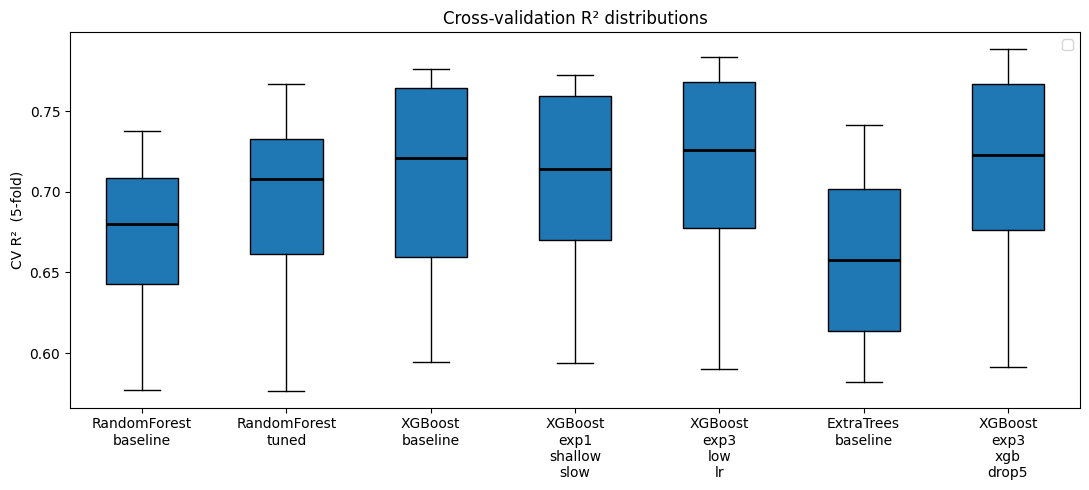

In [435]:
# CV summary table + box plot
cv_summary = pd.DataFrame({
    name: {"cv_r2_mean": scores.mean(), "cv_r2_std": scores.std()}
    for name, scores in cv_scores.items()
}).T.sort_values("cv_r2_mean", ascending=False).reset_index(names="model")

display(
    cv_summary.style.format({"cv_r2_mean": "{:.4f}", "cv_r2_std": "{:.4f}"})
    .background_gradient(subset=["cv_r2_mean"], cmap="RdYlGn")
)

# Log cv_r2_mean + cv_r2_std into each model's existing MLflow run
for name, scores in cv_scores.items():
    runs = mlflow.search_runs(
        experiment_names=[EXPERIMENT_NAME],
        filter_string=f"run_name = '{name}'",
    )
    if runs.empty:
        print(f"WARNING: no MLflow run found for '{name}', skipping CV logging")
        continue
    run_id = runs.iloc[0]["run_id"]
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metric("cv_r2_mean", float(scores.mean()))
        mlflow.log_metric("cv_r2_std",  float(scores.std()))

print("CV R² logged to MLflow runs.")

# Box plot of per-fold R² distributions
fig, ax = plt.subplots(figsize=(11, 5))
labels = list(cv_scores.keys())
ax.boxplot(
    [cv_scores[n] for n in labels],
    labels=[n.replace("_", "\n") for n in labels],
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
ax.set_ylabel("CV R²  (5-fold)")
ax.set_title("Cross-validation R² distributions")
ax.legend()
plt.tight_layout()
plt.show()

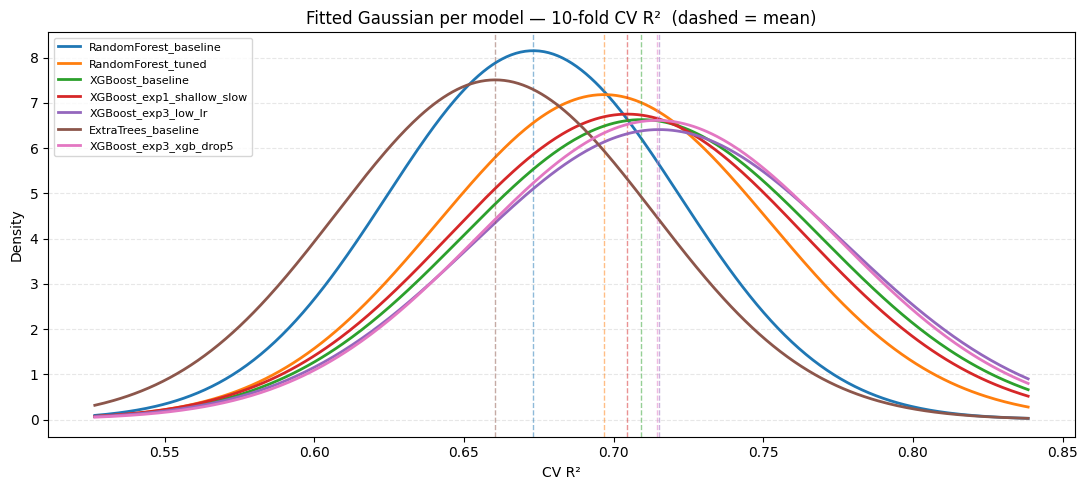

In [436]:
from scipy.stats import norm

fig, ax = plt.subplots(figsize=(11, 5))

colors = plt.cm.tab10.colors
x_grid = np.linspace(
    min(s.min() for s in cv_scores.values()) - 0.05,
    max(s.max() for s in cv_scores.values()) + 0.05,
    400,
)

for (name, scores), color in zip(cv_scores.items(), colors):
    mu, sigma = scores.mean(), scores.std()
    ax.plot(x_grid, norm.pdf(x_grid, mu, sigma), color=color, linewidth=2, label=name)
    ax.axvline(mu, color=color, linewidth=1, linestyle="--", alpha=0.5)

ax.set_xlabel("CV R²")
ax.set_ylabel("Density")
ax.set_title("Fitted Gaussian per model — 10-fold CV R²  (dashed = mean)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

---
### XGBoost exp3 — with vs without feature removal

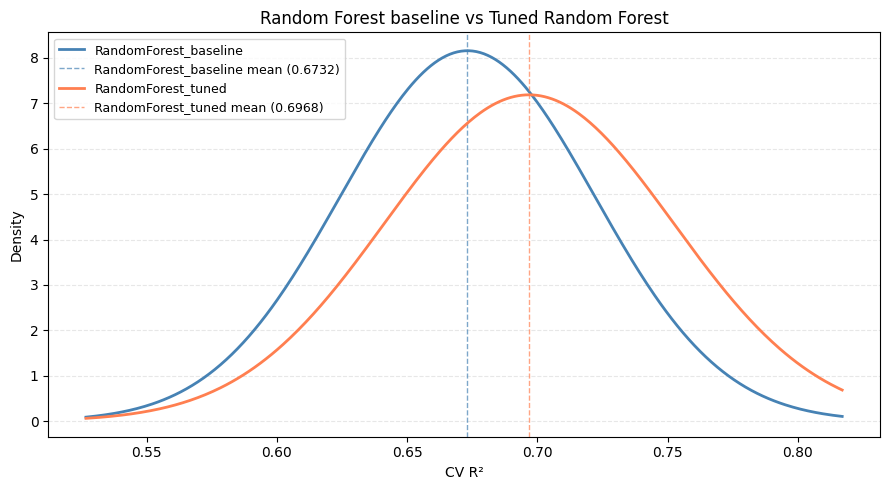

Paired t-test: t=-5.157  p=0.0006  → significant at α=0.05


In [443]:
A = "RandomForest_baseline"
B = "RandomForest_tuned"

scores_a = cv_scores[A]
scores_b = cv_scores[B]

x_grid = np.linspace(
    min(scores_a.min(), scores_b.min()) - 0.05,
    max(scores_a.max(), scores_b.max()) + 0.05,
    400,
)

fig, ax = plt.subplots(figsize=(9, 5))

for scores, color, label in [
    (scores_a, "steelblue", A),
    (scores_b, "coral",     B),
]:
    mu, sigma = scores.mean(), scores.std()
    ax.plot(x_grid, norm.pdf(x_grid, mu, sigma), color=color, linewidth=2, label=label)
    ax.axvline(mu, color=color, linewidth=1, linestyle="--", alpha=0.7,
               label=f"{label} mean ({mu:.4f})")

ax.set_xlabel("CV R²")
ax.set_ylabel("Density")
ax.set_title("Random Forest baseline vs Tuned Random Forest")
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

t, p = ttest_rel(scores_a, scores_b)
print(f"Paired t-test: t={t:.3f}  p={p:.4f}  → {'significant' if p < 0.05 else 'not significant'} at α=0.05")

---
## Statistical significance — paired t-test vs Random Forest baseline

Each model's per-fold CV R² scores are compared against the Random Forest baseline using a paired t-test (H₀: equal mean R²). The same 5 folds are shared across all models, so observations are paired by fold.

- **α = 0.05**: reject H₀ if p < 0.05  
- A two-sided test is used (we care whether the difference goes either way)

In [438]:
from scipy.stats import ttest_rel

ALPHA = 0.05
REFERENCE = "RandomForest_baseline"
ref_scores = cv_scores[REFERENCE]

print(f"Reference: {REFERENCE}  mean R²={ref_scores.mean():.4f}\n")
print(f"{'Challenger':<30s} {'mean diff':>10s} {'t-stat':>8s} {'p-value':>10s}  {'significant?':>14s}")
print("-" * 80)

ttest_rows = []
for name, scores in cv_scores.items():
    if name == REFERENCE:
        continue
    t_stat, p_val = ttest_rel(scores, ref_scores)
    mean_diff = scores.mean() - ref_scores.mean()
    significant = p_val < ALPHA
    marker = "✓  (p < 0.05)" if significant else "✗  (not sig.)"
    print(f"{name:<30s} {mean_diff:>+10.4f} {t_stat:>8.3f} {p_val:>10.4f}  {marker:>14s}")
    ttest_rows.append({
        "challenger": name,
        "challenger_mean_r2": float(scores.mean()),
        "reference_mean_r2": float(ref_scores.mean()),
        "mean_diff": float(mean_diff),
        "t_stat": float(t_stat),
        "p_value": float(p_val),
        "significant_at_0.05": significant,
    })

ttest_df = pd.DataFrame(ttest_rows)
display(ttest_df.style.format({
    "challenger_mean_r2": "{:.4f}", "reference_mean_r2": "{:.4f}",
    "mean_diff": "{:+.4f}", "t_stat": "{:.3f}", "p_value": "{:.4f}",
}))

Reference: RandomForest_baseline  mean R²=0.6732

Challenger                      mean diff   t-stat    p-value    significant?
--------------------------------------------------------------------------------
RandomForest_tuned                +0.0236    5.157     0.0006   ✓  (p < 0.05)
XGBoost_baseline                  +0.0361    5.059     0.0007   ✓  (p < 0.05)
XGBoost_exp1_shallow_slow         +0.0314    4.498     0.0015   ✓  (p < 0.05)
XGBoost_exp3_low_lr               +0.0420    5.740     0.0003   ✓  (p < 0.05)
ExtraTrees_baseline               -0.0127   -1.972     0.0800   ✗  (not sig.)
XGBoost_exp3_xgb_drop5            +0.0413    5.957     0.0002   ✓  (p < 0.05)


,challenger,challenger_mean_r2,reference_mean_r2,mean_diff,t_stat,p_value,significant_at_0.05
0,RandomForest_tuned,0.6968,0.6732,+0.0236,5.157,0.0006,True
1,XGBoost_baseline,0.7093,0.6732,+0.0361,5.059,0.0007,True
2,XGBoost_exp1_shallow_slow,0.7046,0.6732,+0.0314,4.498,0.0015,True
3,XGBoost_exp3_low_lr,0.7152,0.6732,+0.0420,5.740,0.0003,True
4,ExtraTrees_baseline,0.6604,0.6732,-0.0127,-1.972,0.0800,False
5,XGBoost_exp3_xgb_drop5,0.7145,0.6732,+0.0413,5.957,0.0002,True


In [439]:
with mlflow.start_run(run_name="ttest_summary"):
    mlflow.log_param("reference_model", REFERENCE)
    mlflow.log_param("cv_folds", CV_FOLDS)
    mlflow.log_param("alpha", ALPHA)
    mlflow.log_metric("reference_cv_r2_mean", float(ref_scores.mean()))
    mlflow.log_metric("reference_cv_r2_std",  float(ref_scores.std()))
    for row in ttest_rows:
        tag = row["challenger"].replace(" ", "_")
        mlflow.log_metric(f"ttest_pvalue_{tag}", row["p_value"])
        mlflow.log_metric(f"ttest_mean_diff_{tag}", row["mean_diff"])

🏃 View run ttest_summary at: https://172.27.62.170:5001/#/experiments/9/runs/51f7bdc601db40839a539b4002e1e736
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/9


## Report figures

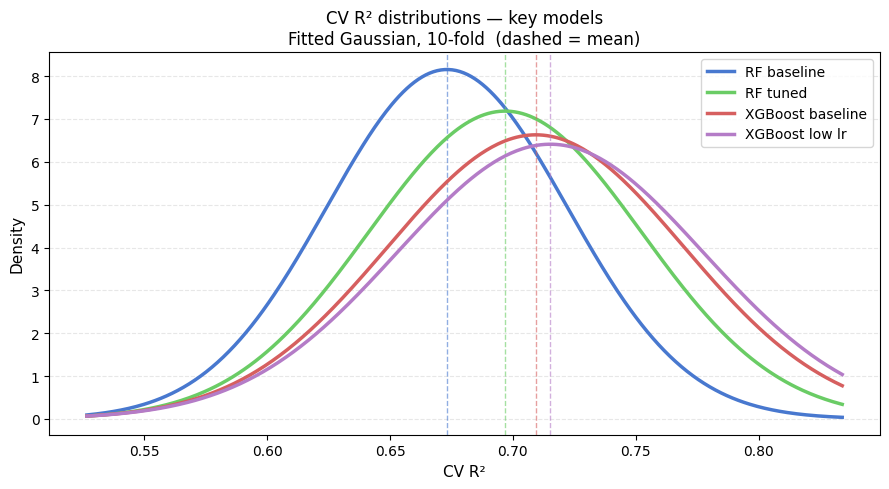

In [440]:
# ── Figure 2: CV R² fitted Gaussians — key 4 models ────────────────────────
key_order = [
    "RandomForest_baseline",
    "RandomForest_tuned",
    "XGBoost_baseline",
    "XGBoost_exp3_low_lr",
]
key_colors = ["#4878cf", "#6acc65", "#d65f5f", "#b47cc7"]
key_labels = [
    "RF baseline",
    "RF tuned",
    "XGBoost baseline",
    "XGBoost low lr",
]

x_min = min(cv_scores[n].min() for n in key_order) - 0.05
x_max = max(cv_scores[n].max() for n in key_order) + 0.05
x_grid = np.linspace(x_min, x_max, 400)

fig, ax = plt.subplots(figsize=(9, 5))
for name, color, label in zip(key_order, key_colors, key_labels):
    scores = cv_scores[name]
    mu, sigma = scores.mean(), scores.std()
    ax.plot(x_grid, norm.pdf(x_grid, mu, sigma), color=color, linewidth=2.5, label=label)
    ax.axvline(mu, color=color, linewidth=1, linestyle="--", alpha=0.6)

ax.set_xlabel("CV R²", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("CV R² distributions — key models\nFitted Gaussian, 10-fold  (dashed = mean)", fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()